In [1]:
# ==========================================
# E-COMMERCE CUSTOMER SEGMENTATION
# K-Means + DBSCAN + PCA + t-SNE
# ==========================================

import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_csv(
    "online_retail.csv"
)

# Standardize column names
column_aliases = {
    "invoice": "InvoiceNo",
    "invoiceno": "InvoiceNo",
    "stockcode": "StockCode",
    "description": "Description",
    "quantity": "Quantity",
    "invoicedate": "InvoiceDate",
    "price": "UnitPrice",
    "unitprice": "UnitPrice",
    "customerid": "CustomerID",
    "country": "Country"
}

rename_columns = {}

for col in df.columns:
    normalized = re.sub(
        r"[^a-z0-9]",
        "",
        str(col).lower()
    )

    if normalized in column_aliases:
        rename_columns[col] = column_aliases[normalized]

df.rename(columns=rename_columns, inplace=True)

required_columns = [
    "InvoiceNo",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn information:")
print(df.info())

Dataset loaded successfully!
Dataset shape: (288190, 8)

First five records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,532657,21314,SMALL GLASS HEART TRINKET POT,12,2010-11-14 11:10:00,2.10,14562.0,United Kingdom
1,563214,22383,LUNCH BAG SUKI DESIGN,2,2011-08-14 12:56:00,1.65,16370.0,United Kingdom
2,507597,22561,WOODEN SCHOOL COLOURING SET,12,2010-05-10 13:21:00,1.65,17700.0,United Kingdom
3,491634,21588,RETRO SPOT GIANT TUBE MATCHES,1,2009-12-11 15:40:00,2.55,17841.0,United Kingdom
4,496007,85232B,SET/3 RUSSIAN DOLL STACKING TINS,3,2010-01-28 12:32:00,4.95,15203.0,United Kingdom



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 288190 entries, 0 to 288189
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    288190 non-null  str    
 1   StockCode    288190 non-null  str    
 2   Description  287065 non-null  str    
 3   Quantity     288190 non-null  int64  
 4   InvoiceDate  288190 non-null  str    
 5   UnitPrice    288190 non-null  float64
 6   CustomerID   222648 non-null  float64
 7   Country      288190 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 36.9 MB
None


In [3]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Number of unique customers
print(
    "\nUnique Customers:",
    df["CustomerID"].nunique()
)

# Number of unique invoices
print(
    "Unique Invoices:",
    df["InvoiceNo"].nunique()
)

# Number of unique products
print(
    "Unique Products:",
    df["StockCode"].nunique()
)

# Countries
if "Country" in df.columns:
    print(
        "Countries:",
        df["Country"].nunique()
    )

Rows: 288190
Columns: 8

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 288190 entries, 0 to 288189
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    288190 non-null  str    
 1   StockCode    288190 non-null  str    
 2   Description  287065 non-null  str    
 3   Quantity     288190 non-null  int64  
 4   InvoiceDate  288190 non-null  str    
 5   UnitPrice    288190 non-null  float64
 6   CustomerID   222648 non-null  float64
 7   Country      288190 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 36.9 MB
None

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,288190,39598,537434,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,288190,4826,85123A,1542,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,287065,5198,WHITE HANGING HEART T-LIGHT HOLDER,1562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,288190.0,NaN,NaN,NaN,10.06705,161.507561,-9360.0,1.0,3.0,10.0,74215.0
InvoiceDate,288190,36816,2010-12-06 16:57:00,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,288190.0,NaN,NaN,NaN,4.409201,145.655128,-44031.79,1.25,2.1,4.13,25111.09
CustomerID,222648.0,NaN,NaN,NaN,15321.904226,1695.405603,12346.0,13971.0,15251.0,16791.0,18287.0
Country,288190,43,United Kingdom,264827,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
InvoiceNo          0
StockCode          0
Description     1125
Quantity           0
InvoiceDate        0
UnitPrice          0
CustomerID     65542
Country            0
dtype: int64

Unique Customers: 5695
Unique Invoices: 39598
Unique Products: 4826
Countries: 43


In [4]:
# Keep a copy of original dataset
data = df.copy()

original_rows = len(data)

# Convert columns to appropriate data types
data["InvoiceNo"] = (
    data["InvoiceNo"]
    .astype("string")
    .str.strip()
)

data["InvoiceDate"] = pd.to_datetime(
    data["InvoiceDate"],
    errors="coerce",
    dayfirst=True
)

data["CustomerID"] = pd.to_numeric(
    data["CustomerID"],
    errors="coerce"
)

data["Quantity"] = pd.to_numeric(
    data["Quantity"],
    errors="coerce"
)

data["UnitPrice"] = pd.to_numeric(
    data["UnitPrice"],
    errors="coerce"
)

# Remove missing essential values
data.dropna(
    subset=[
        "InvoiceNo",
        "InvoiceDate",
        "CustomerID",
        "Quantity",
        "UnitPrice"
    ],
    inplace=True
)

# Remove cancelled invoices
data = data[
    ~data["InvoiceNo"].str.upper().str.startswith("C")
]

# Remove invalid quantities and prices
data = data[
    (data["Quantity"] > 0) &
    (data["UnitPrice"] > 0)
]

# Convert customer IDs to integer strings
data["CustomerID"] = (
    data["CustomerID"]
    .astype("int64")
    .astype(str)
)

# Calculate transaction revenue
data["Revenue"] = (
    data["Quantity"] *
    data["UnitPrice"]
)

data.reset_index(drop=True, inplace=True)

print("Original rows:", original_rows)
print("Cleaned rows:", len(data))
print("Removed rows:", original_rows - len(data))

print("\nCleaned dataset:")
display(data.head())

print("\nRemaining missing values:")
print(data.isnull().sum())

print("\nTotal revenue:", data["Revenue"].sum())

C:\Users\kunal\AppData\Local\Temp\ipykernel_6700\1072357167.py:13: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  data["InvoiceDate"] = pd.to_datetime(


Original rows: 288190
Cleaned rows: 217589
Removed rows: 70601

Cleaned dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,532657,21314,SMALL GLASS HEART TRINKET POT,12,2010-11-14 11:10:00,2.10,14562,United Kingdom,25.20
1,563214,22383,LUNCH BAG SUKI DESIGN,2,2011-08-14 12:56:00,1.65,16370,United Kingdom,3.30
2,507597,22561,WOODEN SCHOOL COLOURING SET,12,2010-05-10 13:21:00,1.65,17700,United Kingdom,19.80
3,491634,21588,RETRO SPOT GIANT TUBE MATCHES,1,2009-12-11 15:40:00,2.55,17841,United Kingdom,2.55
4,496007,85232B,SET/3 RUSSIAN DOLL STACKING TINS,3,2010-01-28 12:32:00,4.95,15203,United Kingdom,14.85



Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

Total revenue: 4776853.9860000005


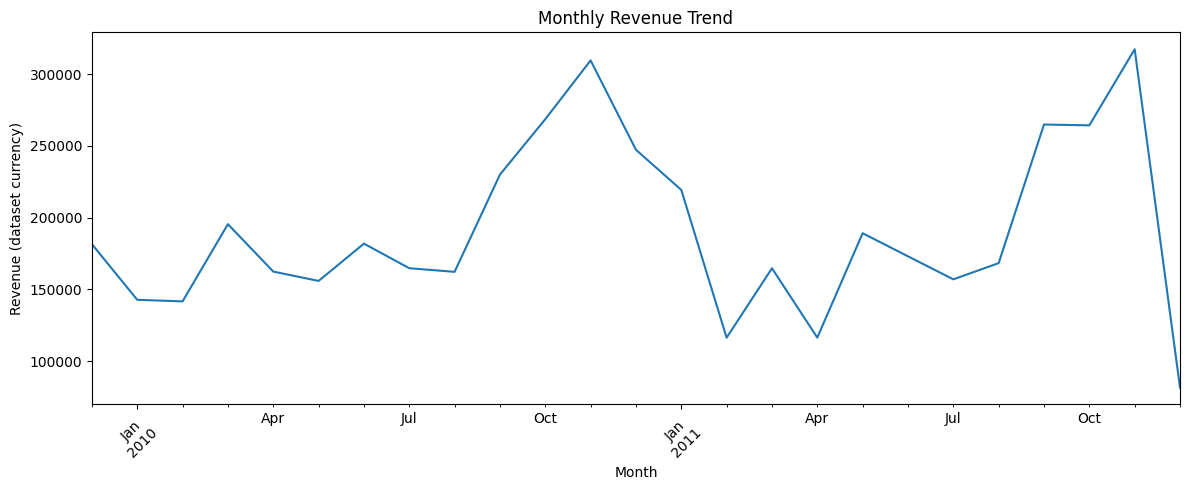

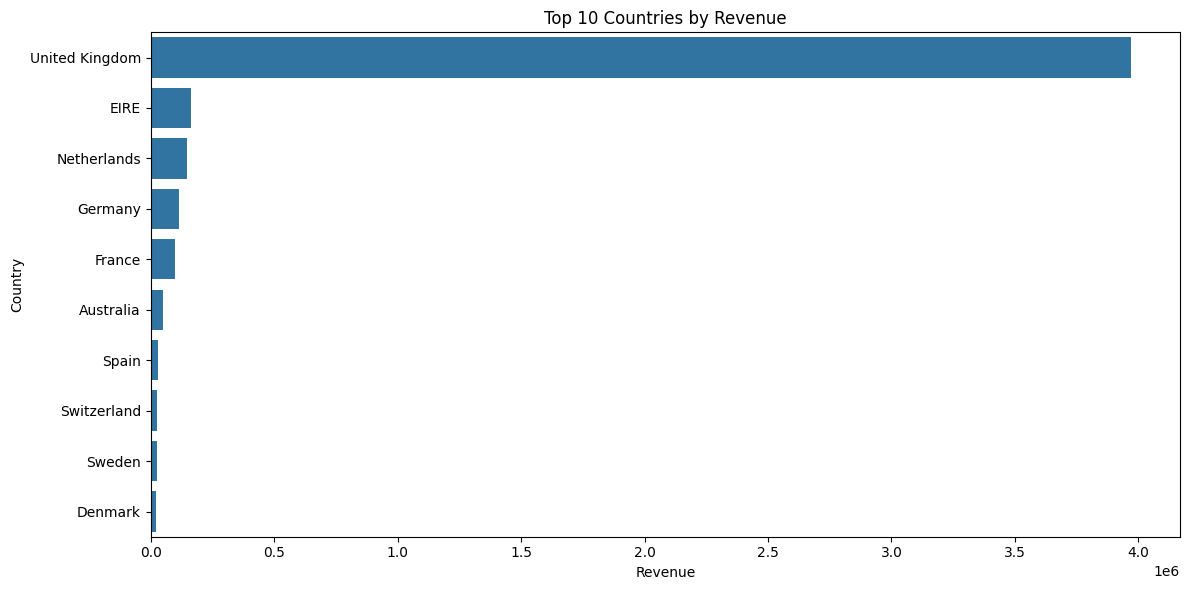

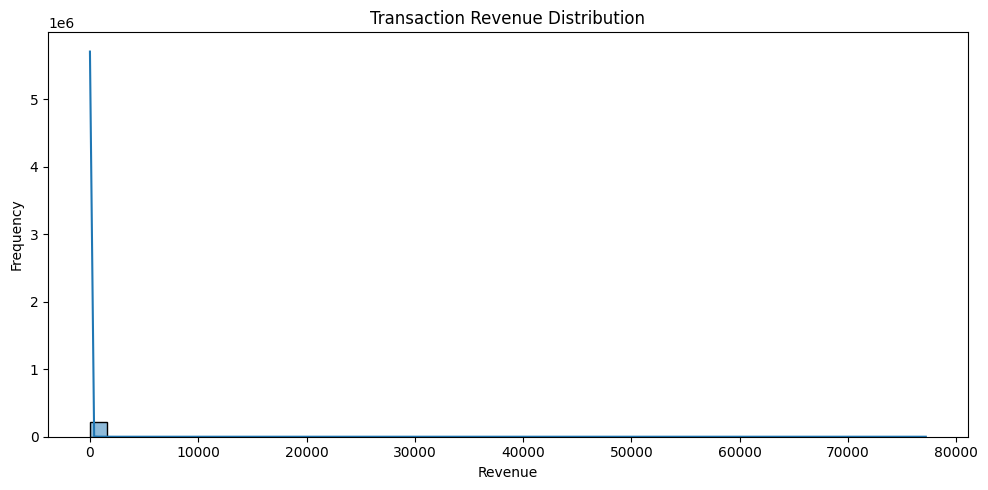

In [5]:
# Revenue by month
monthly_revenue = (
    data.set_index("InvoiceDate")
    .resample("ME")["Revenue"]
    .sum()
)

plt.figure(figsize=(12, 5))

monthly_revenue.plot()

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# Top 10 countries by revenue
country_revenue = (
    data.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=country_revenue.values,
    y=country_revenue.index
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


# Transaction revenue distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data["Revenue"],
    bins=50,
    kde=True
)

plt.title("Transaction Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [6]:
# Reference date:
# One day after the latest transaction in the dataset

reference_date = (
    data["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

# Calculate RFM metrics
rfm = data.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (
            reference_date - x.max().normalize()
        ).days
    ),

    Frequency=(
        "InvoiceNo",
        "nunique"
    ),

    Monetary=(
        "Revenue",
        "sum"
    )
)

rfm = rfm.reset_index()

# Remove any invalid RFM rows
rfm = rfm[
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

print("RFM dataset generated!")

print("\nRFM Dataset Shape:")
print(rfm.shape)

print("\nFirst five customers:")
display(rfm.head())

print("\nRFM Statistical Summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM dataset generated!

RFM Dataset Shape:
(5655, 4)

First five customers:


,CustomerID,Recency,Frequency,Monetary
0,12346,326,6,77300.45
1,12347,40,7,1316.67
2,12348,76,5,592.24
3,12349,19,4,984.56
4,12350,311,1,60.70



RFM Statistical Summary:


,Recency,Frequency,Monetary
count,5655.000000,5655.000000,5655.000000
mean,203.344828,5.714943,844.713349
std,209.199306,11.233639,4162.206777
min,1.000000,1.000000,0.380000
25%,27.000000,1.000000,98.450000
50%,99.000000,3.000000,249.680000
75%,381.000000,6.000000,665.775000
max,739.000000,359.000000,166014.990000


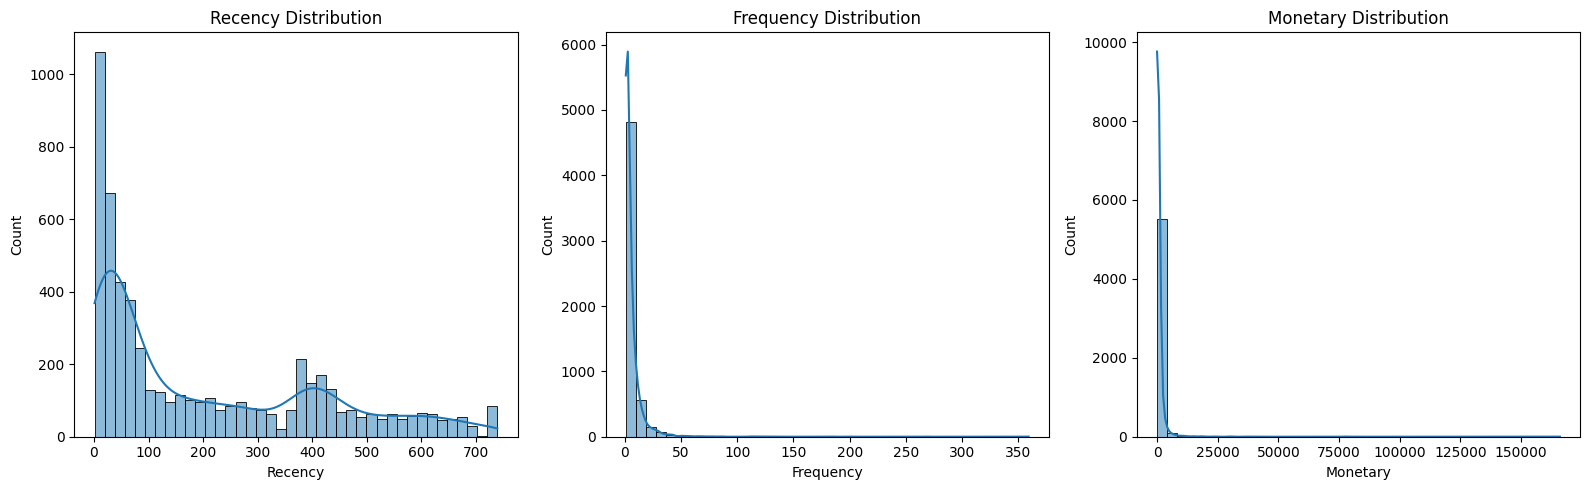

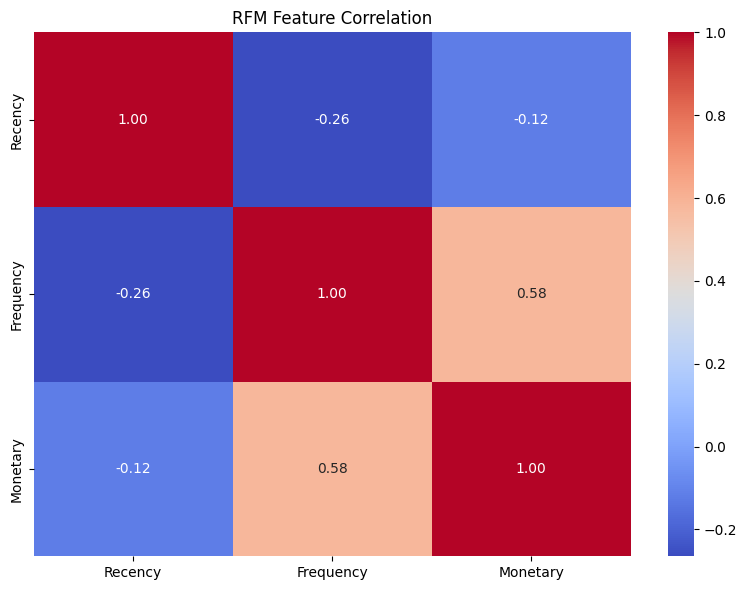

In [7]:
rfm_features = [
    "Recency",
    "Frequency",
    "Monetary"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, feature in zip(axes, rfm_features):

    sns.histplot(
        rfm[feature],
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{feature} Distribution")

plt.tight_layout()


plt.show()


# RFM correlation matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm[rfm_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RFM Feature Correlation")

plt.tight_layout()


plt.show()

In [8]:
# Apply logarithmic transformation
rfm_log = np.log1p(
    rfm[rfm_features]
)

# Feature scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(rfm_log)

print("Log transformation completed.")
print("Feature scaling completed.")

print("\nScaled feature matrix shape:")
print(X_scaled.shape)

print("\nFirst five scaled records:")
print(X_scaled[:5])

Log transformation completed.
Feature scaling completed.

Scaled feature matrix shape:
(5655, 3)

First five scaled records:
[[ 0.85284094  0.56938904  4.06936252]
 [-0.51503875  0.74048665  1.15929888]
 [-0.09985461  0.37187134  0.58896992]
 [-0.98793612  0.13825749  0.95174877]
 [ 0.82190669 -1.03581217 -1.02857363]]


Explained Variance Ratio:
[0.75594029 0.1904959  0.05356381]

Cumulative Explained Variance: [0.75594029 0.94643619 1.        ]


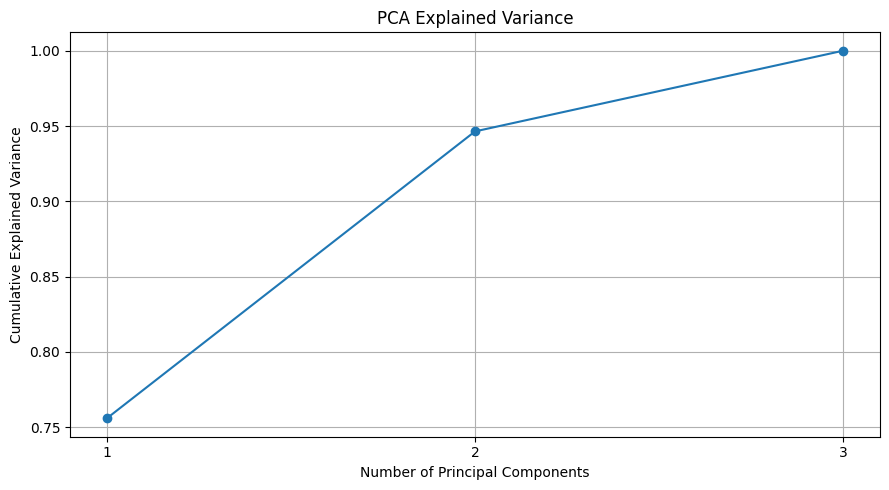


PCA Output Shape:
(5655, 2)
Variance retained by two components: 0.9464361887066233


In [9]:
# Fit PCA on the scaled RFM features
pca_full = PCA(
    random_state=42
)

pca_full.fit(X_scaled)

# Explained variance
explained_variance = (
    pca_full.explained_variance_ratio_
)

print("Explained Variance Ratio:")
print(explained_variance)

print(
    "\nCumulative Explained Variance:",
    explained_variance.cumsum()
)

# Plot explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance.cumsum(),
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True)

plt.tight_layout()


plt.show()


# Reduce data to two dimensions
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_scaled)

print("\nPCA Output Shape:")
print(X_pca.shape)

print(
    "Variance retained by two components:",
    pca.explained_variance_ratio_.sum()
)

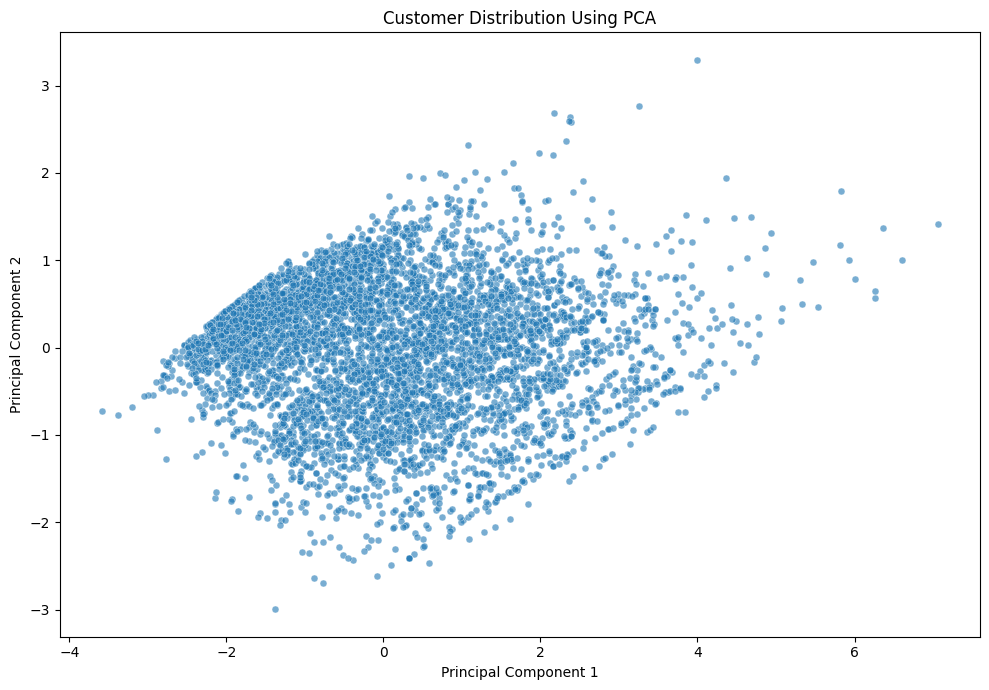

In [10]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    s=25,
    alpha=0.6
)

plt.title("Customer Distribution Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()


plt.show()

,K,Inertia,Silhouette Score
0,2,8329.810141,0.430611
1,3,6159.170967,0.344437
2,4,4771.730435,0.360779
3,5,4025.943450,0.332336
4,6,3486.086394,0.324565
5,7,3107.525042,0.300071
6,8,2816.424559,0.299738
7,9,2573.233317,0.293256


Best K based on tested silhouette scores: 2


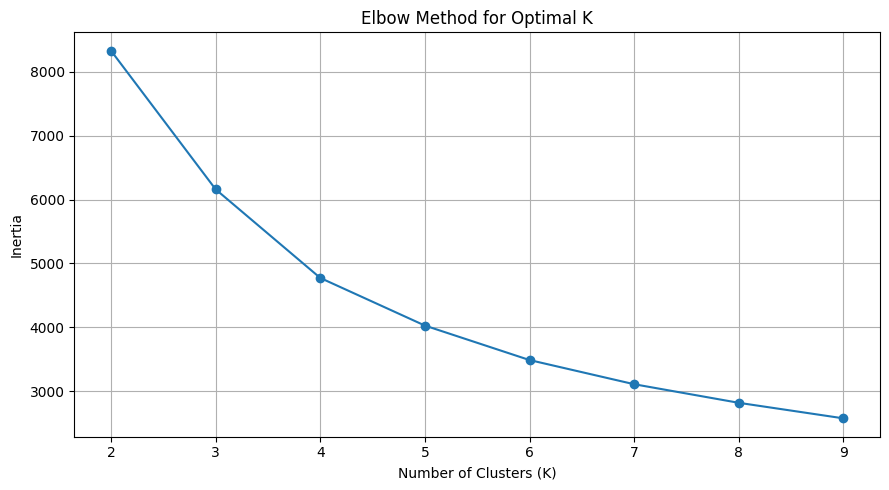

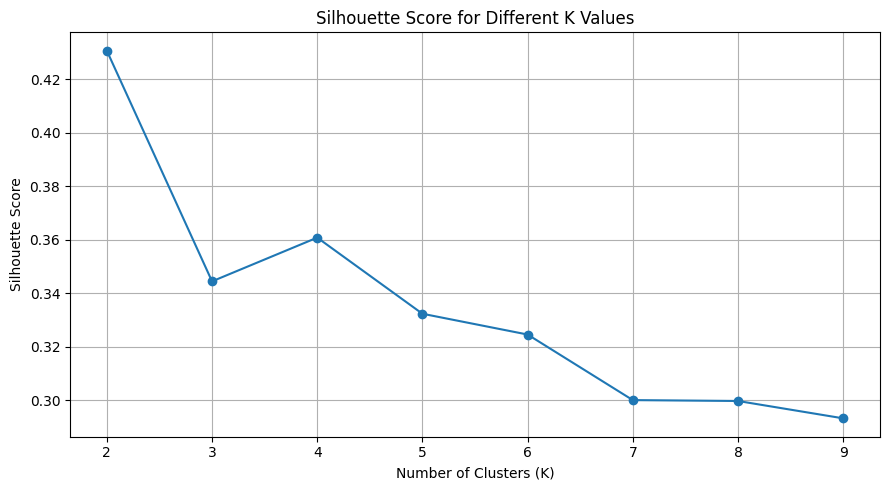

In [11]:
# Test different cluster counts
k_values = range(2, 10)

inertia_values = []
silhouette_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(3000, len(X_scaled)),
        random_state=42
    )

    silhouette_values.append(score)

# Display scores
results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results)

# Select K with the highest tested silhouette score
best_k = int(
    results.loc[
        results["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best K based on tested silhouette scores:", best_k)


# Plot elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.grid(True)

plt.tight_layout()

plt.show()


# Plot silhouette scores
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.grid(True)

plt.tight_layout()


plt.show()

K-Means clustering completed!

Customer count in each cluster:
KMeansCluster
0    2276
1    3379
Name: count, dtype: int64


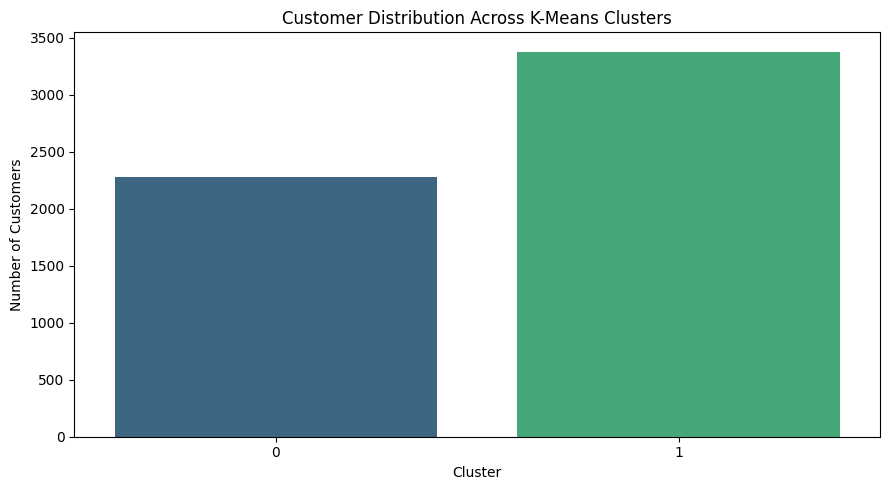

In [12]:
# Train final K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Store cluster labels
rfm["KMeansCluster"] = kmeans_labels

print("K-Means clustering completed!")

print("\nCustomer count in each cluster:")

print(
    rfm["KMeansCluster"]
    .value_counts()
    .sort_index()
)

# Save cluster counts chart
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="KMeansCluster",
    hue="KMeansCluster",
    palette="viridis",
    legend=False
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()


plt.show()

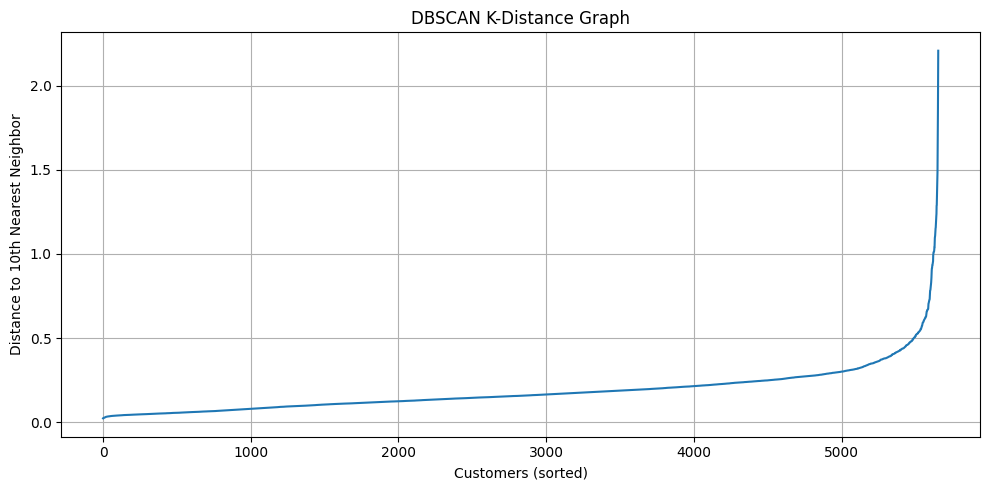

In [13]:
# DBSCAN parameters
MIN_SAMPLES = 10

# Calculate nearest-neighbour distances
neighbors = NearestNeighbors(
    n_neighbors=MIN_SAMPLES
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(
    X_scaled
)

# Sort distances
k_distances = np.sort(
    distances[:, -1]
)

# Plot k-distance graph
plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Customers (sorted)")
plt.ylabel("Distance to 10th Nearest Neighbor")

plt.title("DBSCAN K-Distance Graph")
plt.grid(True)

plt.tight_layout()


plt.show()

In [14]:
# Starting epsilon value.
# Inspect the k-distance graph and change this value
# if necessary.

DBSCAN_EPS = 0.8

dbscan = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=MIN_SAMPLES
)

dbscan_labels = dbscan.fit_predict(
    X_scaled
)

# Store labels
rfm["DBSCANCluster"] = dbscan_labels

# Cluster information
unique_labels = np.unique(dbscan_labels)

number_of_clusters = len(
    unique_labels[unique_labels != -1]
)

noise_points = np.sum(
    dbscan_labels == -1
)

noise_percentage = (
    noise_points / len(dbscan_labels)
) * 100

print("DBSCAN clustering completed!")

print(
    "Number of clusters:",
    number_of_clusters
)

print(
    "Number of noise points:",
    noise_points
)

print(
    "Noise percentage:",
    round(noise_percentage, 2),
    "%"
)

print("\nCluster distribution:")

print(
    pd.Series(dbscan_labels)
    .value_counts()
    .sort_index()
)

DBSCAN clustering completed!
Number of clusters: 1
Number of noise points: 27
Noise percentage: 0.48 %

Cluster distribution:
-1      27
 0    5628
Name: count, dtype: int64


In [15]:
# Starting epsilon value.
# Inspect the k-distance graph and change this value
# if necessary.

DBSCAN_EPS = 0.8

dbscan = DBSCAN(
    eps=DBSCAN_EPS,
    min_samples=MIN_SAMPLES
)

dbscan_labels = dbscan.fit_predict(
    X_scaled
)

# Store labels
rfm["DBSCANCluster"] = dbscan_labels

# Cluster information
unique_labels = np.unique(dbscan_labels)

number_of_clusters = len(
    unique_labels[unique_labels != -1]
)

noise_points = np.sum(
    dbscan_labels == -1
)

noise_percentage = (
    noise_points / len(dbscan_labels)
) * 100

print("DBSCAN clustering completed!")

print(
    "Number of clusters:",
    number_of_clusters
)

print(
    "Number of noise points:",
    noise_points
)

print(
    "Noise percentage:",
    round(noise_percentage, 2),
    "%"
)

print("\nCluster distribution:")

print(
    pd.Series(dbscan_labels)
    .value_counts()
    .sort_index()
)

DBSCAN clustering completed!
Number of clusters: 1
Number of noise points: 27
Noise percentage: 0.48 %

Cluster distribution:
-1      27
 0    5628
Name: count, dtype: int64


In [16]:
# K-Means evaluation
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels,
    sample_size=min(3000, len(X_scaled)),
    random_state=42
)

kmeans_db_index = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

print("========== K-MEANS EVALUATION ==========")

print(
    "Silhouette Score:",
    round(kmeans_silhouette, 4)
)

print(
    "Davies-Bouldin Index:",
    round(kmeans_db_index, 4)
)


# DBSCAN evaluation
non_noise_mask = dbscan_labels != -1

dbscan_non_noise_labels = dbscan_labels[
    non_noise_mask
]

distinct_dbscan_clusters = np.unique(
    dbscan_non_noise_labels
)

dbscan_silhouette = None
dbscan_db_index = None

# Calculate metrics only if at least two
# non-noise clusters exist.

if (
    len(distinct_dbscan_clusters) >= 2
    and non_noise_mask.sum() > len(distinct_dbscan_clusters)
):

    dbscan_silhouette = silhouette_score(
        X_scaled[non_noise_mask],
        dbscan_non_noise_labels,
        sample_size=min(
            3000,
            non_noise_mask.sum()
        ),
        random_state=42
    )

    dbscan_db_index = davies_bouldin_score(
        X_scaled[non_noise_mask],
        dbscan_non_noise_labels
    )

print("\n========== DBSCAN EVALUATION ==========")

print(
    "Number of Clusters:",
    number_of_clusters
)

print(
    "Noise Percentage:",
    round(noise_percentage, 2),
    "%"
)

print(
    "Silhouette Score:",
    (
        round(dbscan_silhouette, 4)
        if dbscan_silhouette is not None
        else "Not defined"
    )
)

print(
    "Davies-Bouldin Index:",
    (
        round(dbscan_db_index, 4)
        if dbscan_db_index is not None
        else "Not defined"
    )
)


# Save evaluation results
evaluation = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Clusters": best_k,
        "Silhouette Score": kmeans_silhouette,
        "Davies-Bouldin Index": kmeans_db_index,
        "Noise Percentage": 0
    },
    {
        "Algorithm": "DBSCAN",
        "Clusters": number_of_clusters,
        "Silhouette Score": dbscan_silhouette,
        "Davies-Bouldin Index": dbscan_db_index,
        "Noise Percentage": noise_percentage
    }
])

print("\nModel Comparison:")
display(evaluation)

========== K-MEANS EVALUATION ==========
Silhouette Score: 0.4306
Davies-Bouldin Index: 0.8836

========== DBSCAN EVALUATION ==========
Number of Clusters: 1
Noise Percentage: 0.48 %
Silhouette Score: Not defined
Davies-Bouldin Index: Not defined

Model Comparison:


,Algorithm,Clusters,Silhouette Score,Davies-Bouldin Index,Noise Percentage
0,K-Means,2,0.430611,0.883632,0.000000
1,DBSCAN,1,NaN,NaN,0.477454


In [17]:
# Calculate a valid perplexity for the dataset
perplexity = min(
    30,
    max(2, (len(X_scaled) - 1) // 3)
)

# Create t-SNE model
tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=42,
    max_iter=1000
)

# Fit t-SNE
X_tsne = tsne.fit_transform(X_scaled)

# Create visualization dataframe
tsne_results = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "KMeansCluster": kmeans_labels.astype(str),
    "DBSCANCluster": dbscan_labels.astype(str)
})

print("t-SNE transformation completed!")

print("Output shape:", X_tsne.shape)

t-SNE transformation completed!
Output shape: (5655, 2)


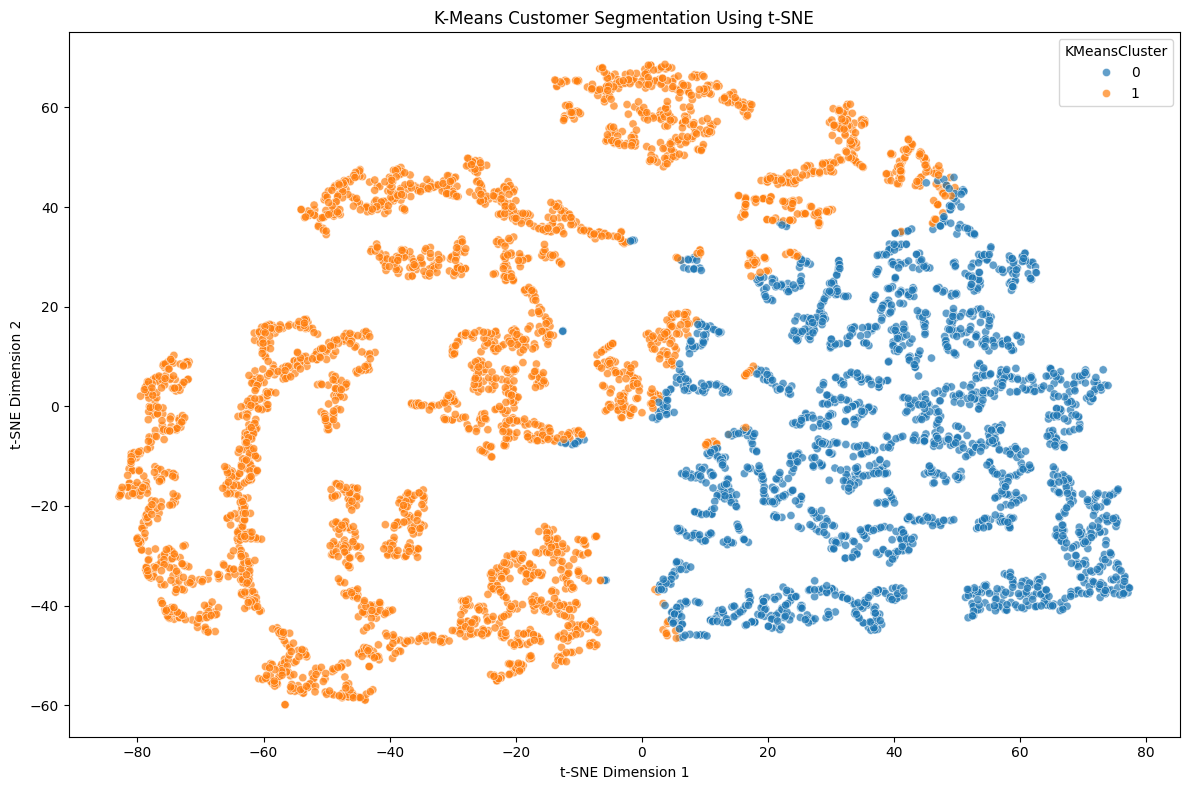

In [18]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=tsne_results,
    x="TSNE1",
    y="TSNE2",
    hue="KMeansCluster",
    palette="tab10",
    s=35,
    alpha=0.7
)

plt.title("K-Means Customer Segmentation Using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.tight_layout()


plt.show()

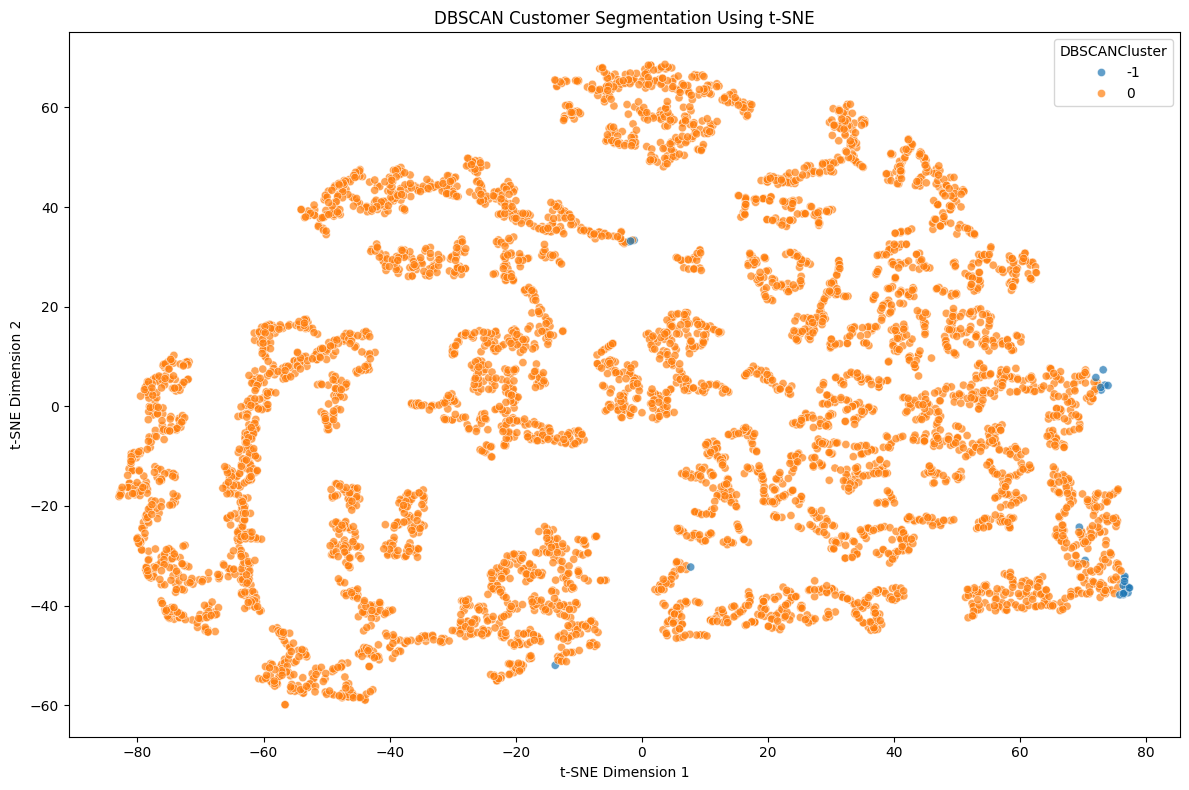

In [19]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=tsne_results,
    x="TSNE1",
    y="TSNE2",
    hue="DBSCANCluster",
    palette="tab10",
    s=35,
    alpha=0.7
)

plt.title("DBSCAN Customer Segmentation Using t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.tight_layout()

plt.show()

In [20]:
# Calculate global RFM thresholds
q25 = rfm[rfm_features].quantile(0.25)
q50 = rfm[rfm_features].quantile(0.50)
q75 = rfm[rfm_features].quantile(0.75)


# Define persona classification function
def assign_persona(row):

    recency = row["MedianRecency"]
    frequency = row["MedianFrequency"]
    monetary = row["MedianMonetary"]

    # Champions
    if (
        recency <= q25["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q75["Monetary"]
    ):
        return "Champions"

    # High-value customers who may be at risk
    elif (
        recency >= q75["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q50["Monetary"]
    ):
        return "At-Risk High-Value Customers"

    # Loyal customers
    elif (
        frequency >= q75["Frequency"] and
        recency <= q75["Recency"]
    ):
        return "Loyal Customers"

    # High monetary value but low frequency
    elif (
        monetary >= q75["Monetary"] and
        frequency <= q50["Frequency"]
    ):
        return "Big Spenders / Occasional Buyers"

    # Recently active customers
    elif (
        recency <= q25["Recency"] and
        frequency <= q50["Frequency"]
    ):
        return "Recent / New Customers"

    # Inactive customers
    elif (
        recency >= q75["Recency"] and
        frequency <= q50["Frequency"] and
        monetary <= q50["Monetary"]
    ):
        return "Hibernating Customers"

    else:
        return "Regular / Developing Customers"


# Marketing strategies
marketing_actions = {

    "Champions":
    "VIP rewards, exclusive offers and loyalty programs",

    "Loyal Customers":
    "Memberships, cross-selling and referral campaigns",

    "At-Risk High-Value Customers":
    "Personalized win-back campaigns and loyalty incentives",

    "Big Spenders / Occasional Buyers":
    "Premium product recommendations and product bundles",

    "Recent / New Customers":
    "Welcome discounts and second-purchase incentives",

    "Hibernating Customers":
    "Reactivation emails and limited-time discounts",

    "Regular / Developing Customers":
    "Personalized recommendations and promotional bundles",

    "Noise / Outlier Customers":
    "Investigate unusual behaviour before launching targeted campaigns"
}


# Profile generator
def create_cluster_profile(data, cluster_column):

    profile = (
        data.groupby(cluster_column)
        .agg(
            CustomerCount=("CustomerID", "nunique"),

            MedianRecency=("Recency", "median"),

            MedianFrequency=("Frequency", "median"),

            MedianMonetary=("Monetary", "median"),

            AverageMonetary=("Monetary", "mean")
        )
        .reset_index()
    )

    profile["Persona"] = profile.apply(
        lambda row: (
            "Noise / Outlier Customers"
            if (
                cluster_column == "DBSCANCluster"
                and row[cluster_column] == -1
            )
            else assign_persona(row)
        ),
        axis=1
    )

    profile["MarketingAction"] = (
        profile["Persona"].map(marketing_actions)
    )

    return profile


# Prepare profile dataset
rfm_profiles = rfm.copy()

# K-Means profiles
kmeans_profile = create_cluster_profile(
    rfm_profiles,
    "KMeansCluster"
)

# DBSCAN profiles
dbscan_profile = create_cluster_profile(
    rfm_profiles,
    "DBSCANCluster"
)

print("K-Means Customer Personas:")
display(kmeans_profile)

print("\nDBSCAN Customer Personas:")
display(dbscan_profile)


K-Means Customer Personas:


,KMeansCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,0,2276,26.0,8.0,793.77,1832.145894,Champions,"VIP rewards, exclusive offers and loyalty prog..."
1,1,3379,303.0,2.0,121.07,179.606372,Regular / Developing Customers,Personalized recommendations and promotional b...



DBSCAN Customer Personas:


,DBSCANCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,-1,27,5.0,56.0,19626.350,38529.449259,Noise / Outlier Customers,Investigate unusual behaviour before launching...
1,0,5628,100.0,3.0,247.075,663.923038,Regular / Developing Customers,Personalized recommendations and promotional b...


In [21]:
# Calculate global RFM thresholds
q25 = rfm[rfm_features].quantile(0.25)
q50 = rfm[rfm_features].quantile(0.50)
q75 = rfm[rfm_features].quantile(0.75)


# Define persona classification function
def assign_persona(row):

    recency = row["MedianRecency"]
    frequency = row["MedianFrequency"]
    monetary = row["MedianMonetary"]

    # Champions
    if (
        recency <= q25["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q75["Monetary"]
    ):
        return "Champions"

    # High-value customers who may be at risk
    elif (
        recency >= q75["Recency"] and
        frequency >= q75["Frequency"] and
        monetary >= q50["Monetary"]
    ):
        return "At-Risk High-Value Customers"

    # Loyal customers
    elif (
        frequency >= q75["Frequency"] and
        recency <= q75["Recency"]
    ):
        return "Loyal Customers"

    # High monetary value but low frequency
    elif (
        monetary >= q75["Monetary"] and
        frequency <= q50["Frequency"]
    ):
        return "Big Spenders / Occasional Buyers"

    # Recently active customers
    elif (
        recency <= q25["Recency"] and
        frequency <= q50["Frequency"]
    ):
        return "Recent / New Customers"

    # Inactive customers
    elif (
        recency >= q75["Recency"] and
        frequency <= q50["Frequency"] and
        monetary <= q50["Monetary"]
    ):
        return "Hibernating Customers"

    else:
        return "Regular / Developing Customers"


# Marketing strategies
marketing_actions = {

    "Champions":
    "VIP rewards, exclusive offers and loyalty programs",

    "Loyal Customers":
    "Memberships, cross-selling and referral campaigns",

    "At-Risk High-Value Customers":
    "Personalized win-back campaigns and loyalty incentives",

    "Big Spenders / Occasional Buyers":
    "Premium product recommendations and product bundles",

    "Recent / New Customers":
    "Welcome discounts and second-purchase incentives",

    "Hibernating Customers":
    "Reactivation emails and limited-time discounts",

    "Regular / Developing Customers":
    "Personalized recommendations and promotional bundles",

    "Noise / Outlier Customers":
    "Investigate unusual behaviour before launching targeted campaigns"
}


# Profile generator
def create_cluster_profile(data, cluster_column):

    profile = (
        data.groupby(cluster_column)
        .agg(
            CustomerCount=("CustomerID", "nunique"),

            MedianRecency=("Recency", "median"),

            MedianFrequency=("Frequency", "median"),

            MedianMonetary=("Monetary", "median"),

            AverageMonetary=("Monetary", "mean")
        )
        .reset_index()
    )

    profile["Persona"] = profile.apply(
        lambda row: (
            "Noise / Outlier Customers"
            if (
                cluster_column == "DBSCANCluster"
                and row[cluster_column] == -1
            )
            else assign_persona(row)
        ),
        axis=1
    )

    profile["MarketingAction"] = (
        profile["Persona"].map(marketing_actions)
    )

    return profile


# Prepare profile dataset
rfm_profiles = rfm.copy()

# K-Means profiles
kmeans_profile = create_cluster_profile(
    rfm_profiles,
    "KMeansCluster"
)

# DBSCAN profiles
dbscan_profile = create_cluster_profile(
    rfm_profiles,
    "DBSCANCluster"
)

print("K-Means Customer Personas:")
display(kmeans_profile)

print("\nDBSCAN Customer Personas:")
display(dbscan_profile)



K-Means Customer Personas:


,KMeansCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,0,2276,26.0,8.0,793.77,1832.145894,Champions,"VIP rewards, exclusive offers and loyalty prog..."
1,1,3379,303.0,2.0,121.07,179.606372,Regular / Developing Customers,Personalized recommendations and promotional b...



DBSCAN Customer Personas:


,DBSCANCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,-1,27,5.0,56.0,19626.350,38529.449259,Noise / Outlier Customers,Investigate unusual behaviour before launching...
1,0,5628,100.0,3.0,247.075,663.923038,Regular / Developing Customers,Personalized recommendations and promotional b...


In [22]:
# Map K-Means cluster IDs to persona names
kmeans_persona_map = (
    kmeans_profile
    .set_index("KMeansCluster")["Persona"]
    .to_dict()
)

# Map DBSCAN cluster IDs to persona names
dbscan_persona_map = (
    dbscan_profile
    .set_index("DBSCANCluster")["Persona"]
    .to_dict()
)

# Add persona information
rfm["KMeansPersona"] = (
    rfm["KMeansCluster"]
    .map(kmeans_persona_map)
)

rfm["DBSCANPersona"] = (
    rfm["DBSCANCluster"]
    .map(dbscan_persona_map)
)

# Add marketing recommendations
rfm["MarketingRecommendation"] = (
    rfm["KMeansPersona"]
    .map(marketing_actions)
)


print("Final customer segmentation generated!")

display(rfm.head(10))

print("\nK-Means Persona Distribution:")

print(
    rfm["KMeansPersona"]
    .value_counts()
)

print("\nDBSCAN Persona Distribution:")

print(
    rfm["DBSCANPersona"]
    .value_counts()
)

Final customer segmentation generated!


,CustomerID,Recency,Frequency,Monetary,KMeansCluster,DBSCANCluster,KMeansPersona,DBSCANPersona,MarketingRecommendation
0,12346,326,6,77300.45,0,-1,Champions,Noise / Outlier Customers,"VIP rewards, exclusive offers and loyalty prog..."
1,12347,40,7,1316.67,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
2,12348,76,5,592.24,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
3,12349,19,4,984.56,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
4,12350,311,1,60.70,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
5,12351,376,1,73.95,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
6,12352,37,9,719.33,0,0,Champions,Regular / Developing Customers,"VIP rewards, exclusive offers and loyalty prog..."
7,12353,205,2,166.90,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
8,12354,233,1,322.62,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...
9,12355,215,2,301.49,1,0,Regular / Developing Customers,Regular / Developing Customers,Personalized recommendations and promotional b...



K-Means Persona Distribution:
KMeansPersona
Regular / Developing Customers    3379
Champions                         2276
Name: count, dtype: int64

DBSCAN Persona Distribution:
DBSCANPersona
Regular / Developing Customers    5628
Noise / Outlier Customers           27
Name: count, dtype: int64


In [23]:
print("=" * 55)
print("E-COMMERCE CUSTOMER SEGMENTATION - FINAL SUMMARY")
print("=" * 55)

print("\nDataset Information")

print("Original transactions:", original_rows)
print("Cleaned transactions:", len(data))
print("Total customers:", len(rfm))

print("\nRFM Metrics")

print("Recency calculated successfully")
print("Frequency calculated successfully")
print("Monetary calculated successfully")

print("\nK-Means Results")

print("Optimal tested K:", best_k)
print(
    "Silhouette Score:",
    round(kmeans_silhouette, 4)
)

print("\nDBSCAN Results")

print("Clusters:", number_of_clusters)
print("Noise Percentage:", round(noise_percentage, 2), "%")

print("\nK-Means Customer Personas")

display(kmeans_profile)

print("\nDBSCAN Customer Personas")

display(dbscan_profile)

print("\nPROJECT COMPLETED SUCCESSFULLY!")

E-COMMERCE CUSTOMER SEGMENTATION - FINAL SUMMARY

Dataset Information
Original transactions: 288190
Cleaned transactions: 217589
Total customers: 5655

RFM Metrics
Recency calculated successfully
Frequency calculated successfully
Monetary calculated successfully

K-Means Results
Optimal tested K: 2
Silhouette Score: 0.4306

DBSCAN Results
Clusters: 1
Noise Percentage: 0.48 %

K-Means Customer Personas


,KMeansCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,0,2276,26.0,8.0,793.77,1832.145894,Champions,"VIP rewards, exclusive offers and loyalty prog..."
1,1,3379,303.0,2.0,121.07,179.606372,Regular / Developing Customers,Personalized recommendations and promotional b...



DBSCAN Customer Personas


,DBSCANCluster,CustomerCount,MedianRecency,MedianFrequency,MedianMonetary,AverageMonetary,Persona,MarketingAction
0,-1,27,5.0,56.0,19626.350,38529.449259,Noise / Outlier Customers,Investigate unusual behaviour before launching...
1,0,5628,100.0,3.0,247.075,663.923038,Regular / Developing Customers,Personalized recommendations and promotional b...



PROJECT COMPLETED SUCCESSFULLY!
